# Q6: Regression – Real Estate Price Prediction
**Aim:** To predict property prices using simple, multiple and polynomial regression.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("06_Regression_House_Prices.csv")
except FileNotFoundError:
    np.random.seed(42)
    area = np.random.randint(600, 3500, 50)
    bed = np.clip(np.round(area / 700) + np.random.randint(-1, 2, 50), 1, 5).astype(int)
    df = pd.DataFrame({"Property_ID": [f"H{i:02d}" for i in range(1, 51)], "Area_Sq_Ft": area, "Bedrooms": bed,
                       "Price_INR_Lakh": (10 + 0.045 * area + 4 * bed + np.random.normal(0, 4, 50)).round(2)})
df.head()

,Property_ID,Area_Sq_Ft,Bedrooms,Price_INR_Lakh
0,H01,1460,2,86.03
1,H02,1894,2,106.78
2,H03,1730,2,99.43
3,H04,1695,1,93.29
4,H05,2238,3,121.88


### 1. EDA

In [3]:
cols = ["Area_Sq_Ft", "Bedrooms", "Price_INR_Lakh"]
print(df[cols].corr().round(3))
df[cols].describe().round(2)

                Area_Sq_Ft  Bedrooms  Price_INR_Lakh
Area_Sq_Ft           1.000     0.855           0.994
Bedrooms             0.855     1.000           0.881
Price_INR_Lakh       0.994     0.881           1.000


,Area_Sq_Ft,Bedrooms,Price_INR_Lakh
count,50.00,50.00,50.00
mean,2087.56,2.90,116.06
std,837.44,1.37,43.09
min,621.00,1.00,41.70
25%,1391.75,2.00,83.42
50%,1989.50,3.00,112.06
75%,2802.75,4.00,153.37
max,3488.00,5.00,192.04


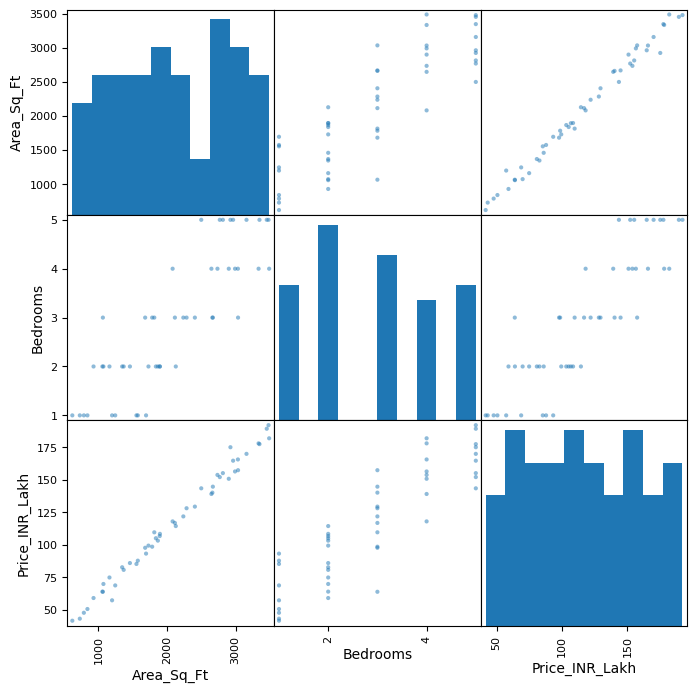

In [4]:
pd.plotting.scatter_matrix(df[cols], figsize=(8, 8))
plt.show()

### 2. Simple linear regression (Area → Price)

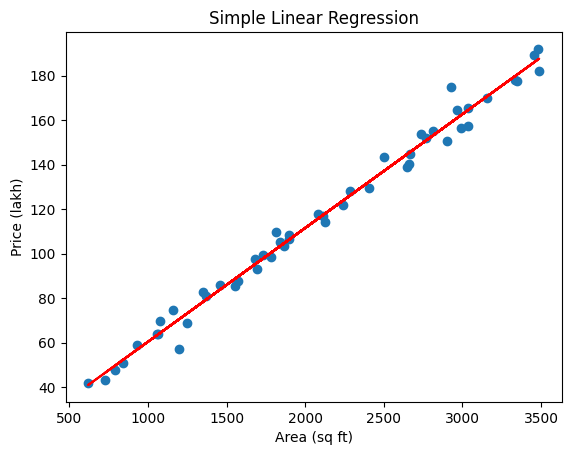

In [5]:
X1 = df[["Area_Sq_Ft"]]
X2 = df[["Area_Sq_Ft", "Bedrooms"]]
y = df["Price_INR_Lakh"]
slr = LinearRegression().fit(X1, y)
plt.scatter(X1, y)
plt.plot(X1, slr.predict(X1), color="red")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (lakh)")
plt.title("Simple Linear Regression")
plt.show()

### 3. Multiple linear regression (Area + Bedrooms → Price)

In [6]:
mlr = LinearRegression().fit(X2, y)
print("SLR: Price = %.3f + %.4f*Area" % (slr.intercept_, slr.coef_[0]))
print("MLR: Price = %.3f + %.4f*Area + %.3f*Bedrooms" % (mlr.intercept_, *mlr.coef_))

SLR: Price = 9.289 + 0.0511*Area
MLR: Price = 9.391 + 0.0461*Area + 3.616*Bedrooms


### 4. Coefficients, R², adjusted R², MAE, MSE, RMSE

In [7]:
def metrics(model, X, y):
    pred = model.predict(X)
    n, k = X.shape
    r2 = r2_score(y, pred)
    mse = mean_squared_error(y, pred)
    adj = 1 - (1 - r2) * (n - 1) / (n - k - 1) if n - k - 1 > 0 else np.nan
    return {"R2": r2, "Adj_R2": adj,
            "MAE": mean_absolute_error(y, pred), "MSE": mse, "RMSE": np.sqrt(mse)}

pd.DataFrame({"SLR": metrics(slr, X1, y), "MLR": metrics(mlr, X2, y)}).round(4)

,SLR,MLR
R2,0.9882,0.9918
Adj_R2,0.9880,0.9914
MAE,3.5160,2.9619
MSE,21.4429,14.9347
RMSE,4.6306,3.8645


### 5. 80:20 train-test split and test evaluation

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=42)
slr_t = LinearRegression().fit(X_train[["Area_Sq_Ft"]], y_train)
mlr_t = LinearRegression().fit(X_train, y_train)
pd.DataFrame({"SLR_Test": metrics(slr_t, X_test[["Area_Sq_Ft"]], y_test),
              "MLR_Test": metrics(mlr_t, X_test, y_test)}).round(4)

,SLR_Test,MLR_Test
R2,0.9837,0.9929
Adj_R2,0.9817,0.9909
MAE,4.2418,2.7103
MSE,22.6997,9.9107
RMSE,4.7644,3.1481


### 6. Residual plots, normality and heteroscedasticity

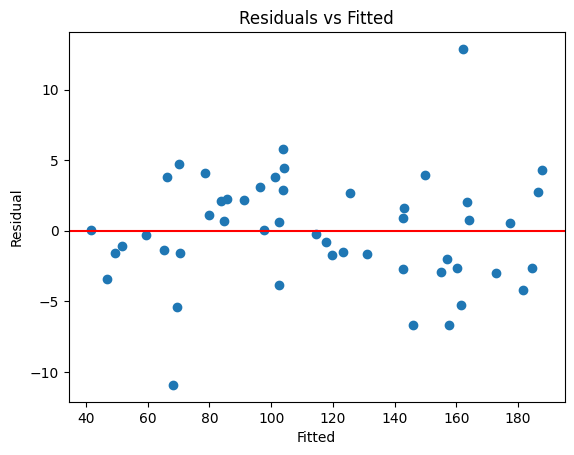

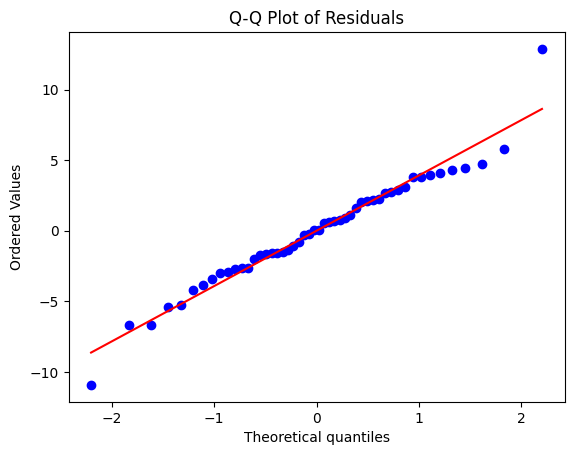

In [9]:
fitted = mlr.predict(X2)
res = y - fitted
plt.scatter(fitted, res)
plt.axhline(0, color="red")
plt.xlabel("Fitted")
plt.ylabel("Residual")
plt.title("Residuals vs Fitted")
plt.show()
stats.probplot(res, plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

In [10]:
sw_p = stats.shapiro(res).pvalue
print("Shapiro-Wilk p = %.4f ->" % sw_p, "Residuals normal" if sw_p > 0.05 else "Not normal")
bp_p = het_breuschpagan(res, sm.add_constant(X2))[1]
print("Breusch-Pagan p = %.4f ->" % bp_p, "Homoscedastic" if bp_p > 0.05 else "Heteroscedastic")

Shapiro-Wilk p = 0.2028 -> Residuals normal
Breusch-Pagan p = 0.5221 -> Homoscedastic


### 7. Leverage and Cook's distance

In [11]:
infl = sm.OLS(y, sm.add_constant(X2)).fit().get_influence()
df["Leverage"] = infl.hat_matrix_diag
df["Cooks_D"] = infl.cooks_distance[0]
n, p = len(df), 3
print("Leverage cut-off 2p/n =", round(2 * p / n, 3), "| Cook's cut-off 4/n =", round(4 / n, 3))
df[(df["Leverage"] > 2 * p / n) | (df["Cooks_D"] > 4 / n)].round(4)

Leverage cut-off 2p/n = 0.12 | Cook's cut-off 4/n = 0.08


,Property_ID,Area_Sq_Ft,Bedrooms,Price_INR_Lakh,Leverage,Cooks_D
6,H07,1066,3,63.94,0.1448,0.1217
20,H21,2924,5,175.07,0.0749,0.3043
46,H47,1200,1,57.38,0.0602,0.1703


### 8. Polynomial regression (degree 2) vs linear models

In [12]:
poly = PolynomialFeatures(degree=2, include_bias=False)
Xp_train = poly.fit_transform(X_train)
Xp_test = poly.transform(X_test)
pr = LinearRegression().fit(Xp_train, y_train)
pd.DataFrame({"SLR": metrics(slr_t, X_test[["Area_Sq_Ft"]], y_test),
              "MLR": metrics(mlr_t, X_test, y_test),
              "Poly_2": metrics(pr, Xp_test, y_test)}).round(4)

,SLR,MLR,Poly_2
R2,0.9837,0.9929,0.9936
Adj_R2,0.9817,0.9909,0.9856
MAE,4.2418,2.7103,2.5228
MSE,22.6997,9.9107,8.9252
RMSE,4.7644,3.1481,2.9875


The model with higher test R² and lower RMSE is better. If Poly_2 is not clearly better, the simpler linear model is preferred.

### 9. Predict price: 2000 sq ft, 3 bedrooms

In [13]:
new = pd.DataFrame({"Area_Sq_Ft": [2000], "Bedrooms": [3]})
print("Predicted price (MLR): %.2f lakh" % mlr.predict(new)[0])

Predicted price (MLR): 112.39 lakh


### 10. Properties with absolute error > ₹5 lakh

In [14]:
df["Predicted"] = mlr.predict(X2).round(2)
df["Abs_Error"] = (y - df["Predicted"]).abs().round(2)
df[df["Abs_Error"] > 5][["Property_ID", "Area_Sq_Ft", "Bedrooms", "Price_INR_Lakh", "Predicted", "Abs_Error"]]

,Property_ID,Area_Sq_Ft,Bedrooms,Price_INR_Lakh,Predicted,Abs_Error
6,H07,1066,3,63.94,69.35,5.41
14,H15,2991,4,156.44,161.67,5.23
18,H19,1815,3,109.66,103.86,5.80
20,H21,2924,5,175.07,162.19,12.88
24,H25,2900,4,150.82,157.47,6.65
29,H30,2647,4,139.13,145.82,6.69
46,H47,1200,1,57.38,68.30,10.92


**Result:** Simple, multiple and polynomial regression models were built, evaluated and diagnosed, and the property price was predicted.